# Lab 1 — Intro to Behavioral TV Data
Name: YEVHENII KOZLOV | Group: KM-41

## Setup

In [1]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")  # Colab and Kaggle
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

In [2]:
programs.head()

,telecast_id,network_code,network_name,network_type,program_name,episode_name,genre,program_type,broadcast_date,daypart,start_ts,end_ts,duration_min,is_live,is_repeat
0,1000001,ABC,ABC,broadcast,Good Morning America First Look,Episode 196,News,news,2024-10-01,Early Morning,2024-10-01 06:00:00,2024-10-01 07:00:00,60,True,False
1,1000002,ABC,ABC,broadcast,Good Morning America,"Rachel Platten, Dr. Karen Knudsen",Talk Show,talk,2024-10-01,Early Morning,2024-10-01 07:00:00,2024-10-01 09:00:00,120,True,False
2,1000003,ABC,ABC,broadcast,Local / Syndicated Programming,None,General,local,2024-10-01,Daytime,2024-10-01 09:00:00,2024-10-01 11:00:00,120,False,False
3,1000004,ABC,ABC,broadcast,The View,"Kate McKinnon, Patrice Jetter, Ted Passon",Talk Show,talk,2024-10-01,Daytime,2024-10-01 11:00:00,2024-10-01 12:00:00,60,True,False
4,1000005,ABC,ABC,broadcast,Local / Syndicated Programming,None,General,local,2024-10-01,Daytime,2024-10-01 12:00:00,2024-10-01 13:00:00,60,False,False


In [3]:
programs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5841 entries, 0 to 5840
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   telecast_id     5841 non-null   int64         
 1   network_code    5841 non-null   object        
 2   network_name    5841 non-null   object        
 3   network_type    5841 non-null   object        
 4   program_name    5841 non-null   object        
 5   episode_name    1454 non-null   object        
 6   genre           5841 non-null   object        
 7   program_type    5841 non-null   object        
 8   broadcast_date  5841 non-null   object        
 9   daypart         5841 non-null   object        
 10  start_ts        5841 non-null   datetime64[us]
 11  end_ts          5841 non-null   datetime64[us]
 12  duration_min    5841 non-null   int64         
 13  is_live         5841 non-null   bool          
 14  is_repeat       5841 non-null   bool          
dtypes: b

In [4]:
viewings.head()

,viewing_id,respondent_id,resp_type,guest_attr_ids,network_code,start_ts,end_ts,playback,weight
0,50000001,10014300,H,None,FNC,2024-10-01 06:00:00,2024-10-01 06:03:00,Live,31600
1,50000002,10014301,R,None,FNC,2024-10-01 06:00:00,2024-10-01 06:03:00,Live,42349
2,50000003,10253700,H,None,NBC,2024-10-01 06:00:00,2024-10-01 07:00:00,Live,32395
3,50000004,10253702,R,None,NBC,2024-10-01 06:00:00,2024-10-01 07:00:00,Live,40028
4,50000005,10042000,H,None,ABC,2024-10-01 06:01:00,2024-10-01 06:11:00,Live,31600


In [5]:
viewings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001885 entries, 0 to 1001884
Data columns (total 9 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   viewing_id      1001885 non-null  int64         
 1   respondent_id   1001885 non-null  int64         
 2   resp_type       1001885 non-null  object        
 3   guest_attr_ids  11996 non-null    object        
 4   network_code    1001885 non-null  object        
 5   start_ts        1001885 non-null  datetime64[us]
 6   end_ts          1001885 non-null  datetime64[us]
 7   playback        1001885 non-null  object        
 8   weight          1001885 non-null  int64         
dtypes: datetime64[us](2), int64(3), object(4)
memory usage: 68.8+ MB


In [6]:
daily_weights.head()

,respondent_id,resp_type,broadcast_date,weight
0,10000100,H,2024-10-01,34466
1,10000101,R,2024-10-01,26577
2,10000102,R,2024-10-01,26417
3,10000300,H,2024-10-01,31600
4,10000301,R,2024-10-01,26577


In [7]:
daily_weights.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 407561 entries, 0 to 407560
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   respondent_id   407561 non-null  int64 
 1   resp_type       407561 non-null  object
 2   broadcast_date  407561 non-null  object
 3   weight          407561 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 12.4+ MB


In [8]:
viewer_attributes.head()

,respondent_id,attr_id,value
0,10000100,104,NaN
1,10000100,802,NaN
2,10000100,815,NaN
3,10000100,822,NaN
4,10000100,833,NaN


In [9]:
viewer_attributes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104679 entries, 0 to 104678
Data columns (total 3 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   respondent_id  104679 non-null  int64  
 1   attr_id        104679 non-null  int64  
 2   value          10216 non-null   float64
dtypes: float64(1), int64(2)
memory usage: 2.4 MB


In [10]:
viewer_attributes[viewer_attributes["value"].notna()]

,respondent_id,attr_id,value
9,10000101,300,48.0
18,10000102,300,47.0
32,10000201,300,32.0
40,10000202,300,2.0
52,10000301,300,48.0
...,...,...,...
104635,10425501,300,64.0
104644,10425502,300,59.0
104651,10425503,300,28.0
104665,10425601,300,35.0


In [11]:
attributes

,attr_id,attr_group,attr_name,value_type,applies_to
0,101,Respondent type,R: panel member (household member),flag,"H,R,L,S"
1,102,Respondent type,L: long-term visitor,flag,"H,R,L,S"
2,103,Respondent type,"S: short-term visitor (guest); id ends 81, 82,...",flag,"H,R,L,S"
3,104,Respondent type,H: household record (id ending 00),flag,"H,R,L,S"
4,201,Sex,Male,flag,"R,L,S"
5,202,Sex,Female,flag,"R,L,S"
6,300,Age,Age in years,numeric,"R,L"
7,302,Age band,2-5,flag,"R,L,S"
8,306,Age band,6-11,flag,"R,L,S"
9,312,Age band,12-17,flag,"R,L,S"


In [12]:
# attribute codes joined to their names
viewer_attributes_named = viewer_attributes.merge(attributes, on="attr_id", how="left")
viewer_attributes_named.head(10)

,respondent_id,attr_id,value,attr_group,attr_name,value_type,applies_to
0,10000100,104,NaN,Respondent type,H: household record (id ending 00),flag,"H,R,L,S"
1,10000100,802,NaN,Household size,2 persons,flag,H
2,10000100,815,NaN,Household income,$100k-$150k,flag,H
3,10000100,822,NaN,Children in household,No children under 18,flag,H
4,10000100,833,NaN,TV reception,Telco / fiber,flag,H
5,10000100,843,NaN,Census region,South,flag,H
6,10000100,852,NaN,County size,B: large,flag,H
7,10000101,101,NaN,Respondent type,R: panel member (household member),flag,"H,R,L,S"
8,10000101,202,NaN,Sex,Female,flag,"R,L,S"
9,10000101,300,48.0,Age,Age in years,numeric,"R,L"


In [13]:
PERSON_TYPES = ["R", "L"]  # S guests are left out of every person number
ONE_MINUTE = pd.Timedelta(minutes=1)

broadcast_days = pd.to_datetime(pd.Series(daily_weights["broadcast_date"].unique()))
N_DAYS = len(broadcast_days)

person_viewings = viewings[viewings["resp_type"].isin(PERSON_TYPES)]

# age and sex of every person
ages = viewer_attributes_named.loc[viewer_attributes_named["attr_id"] == 300].set_index("respondent_id")["value"]
sexes = viewer_attributes_named.loc[viewer_attributes_named["attr_group"] == "Sex"].set_index("respondent_id")["attr_name"]
persons = pd.DataFrame({"age": ages, "sex": sexes})


def weighted_quantile(values, weights, q):
    """Smallest value at which the cumulative weight reaches share q of the total weight."""
    s = pd.DataFrame({"value": np.asarray(values), "weight": np.asarray(weights)}).sort_values("value")
    cum = s["weight"].cumsum()
    return s.loc[cum >= q * s["weight"].sum(), "value"].iloc[0]


print("Broadcast days:", N_DAYS)
persons.head()

Broadcast days: 31


,age,sex
respondent_id,,
10000101,48.0,Female
10000102,47.0,Male
10000201,32.0,Male
10000202,2.0,Male
10000301,48.0,Female


## Task 1.1 — Panel and universe

In [14]:
household_weights = daily_weights[daily_weights["resp_type"] == "H"]
person_weights = daily_weights[daily_weights["resp_type"].isin(PERSON_TYPES)]

print("Telecasts:", programs["telecast_id"].nunique())
print("Programs:", programs["program_name"].nunique())
print("Networks:", programs["network_code"].nunique())
print("Households in panel:", household_weights["respondent_id"].nunique())
print("Persons in panel:", person_weights["respondent_id"].nunique())
print("Households in-tab, average day:", round(len(household_weights) / N_DAYS))
print("Persons in-tab, average day:", round(len(person_weights) / N_DAYS))
print("US TV households represented, average day (M):", f"{household_weights['weight'].sum() / N_DAYS / 1e6:.2f}")
print("US persons represented, average day (M):", f"{person_weights['weight'].sum() / N_DAYS / 1e6:.2f}")

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878
Persons in-tab, average day: 9269
US TV households represented, average day (M): 125.80
US persons represented, average day (M): 317.28


In [15]:
# who is in viewer_attributes but was never in-tab in October
va_ids = set(viewer_attributes["respondent_id"])
dw_ids = set(daily_weights["respondent_id"])
va_households = {i for i in va_ids if i % 100 == 0}
va_persons = va_ids - va_households

print("Persons in viewer_attributes:", len(va_persons))
print("Households in viewer_attributes:", len(va_households))
print("In daily_weights but not in viewer_attributes:", len(dw_ids - va_ids))
print("Persons never in-tab:", len(va_persons - dw_ids))
print("Households never in-tab:", len(va_households - dw_ids))

Persons in viewer_attributes: 10216
Households in viewer_attributes: 4256
In daily_weights but not in viewer_attributes: 0
Persons never in-tab: 6
Households never in-tab: 2


**Question:** Why does viewer_attributes list a few more?

**Answer:** viewer_attributes has attributes for 10216 persons, whereas daily_weights has only 10210. All persons from daily_weights are in viewer_attributes, so the difference is exactly 6 persons who are in the panel but were never in-tab in October (the same is true for 2 households). This can be explained by different factors: they were inactive during the whole month, they have just joined the panel and haven't started reporting yet, or their meter wasn't working.

## Task 1.2 — Average audience by hour of day

In [16]:
def avg_audience_by_hour(views, n_days):
    """Projected average audience (M persons per minute) for each clock hour 0-23."""
    # minutes t with start_ts <= t < end_ts
    first = views["start_ts"].dt.ceil("min")
    n = np.ceil((views["end_ts"] - first) / ONE_MINUTE).clip(lower=0).astype(int).to_numpy()

    # one element per watched minute
    starts = np.repeat(first.to_numpy(), n)
    offsets = np.arange(n.sum()) - np.repeat(np.cumsum(n) - n, n)
    minutes = pd.DatetimeIndex(starts + offsets.astype("timedelta64[m]"))
    weights = np.repeat(views["weight"].to_numpy(), n)

    # weighted minutes per clock hour -> average audience per minute, per day, in millions
    per_hour = pd.Series(weights).groupby(minutes.hour).sum().reindex(range(24), fill_value=0)
    return (per_hour / 60 / n_days / 1e6).rename_axis("hour").rename("avg_audience_M")


# weekday / weekend by broadcast day (06:00-05:59)
session_bday = person_viewings["start_ts"] - pd.Timedelta(hours=6)
is_weekend = session_bday.dt.dayofweek >= 5
n_weekend_days = (broadcast_days.dt.dayofweek >= 5).sum()
n_weekdays = N_DAYS - n_weekend_days

weekday_aud = avg_audience_by_hour(person_viewings[~is_weekend], n_weekdays)
weekend_aud = avg_audience_by_hour(person_viewings[is_weekend], n_weekend_days)

# sessions crossing 06:00 are weighted with their start-day weight
crosses_6am = person_viewings["end_ts"] > session_bday.dt.normalize() + pd.Timedelta(hours=30)
print(f"Sessions crossing 06:00: {100 * crosses_6am.mean():.2f}%")

Sessions crossing 06:00: 0.12%


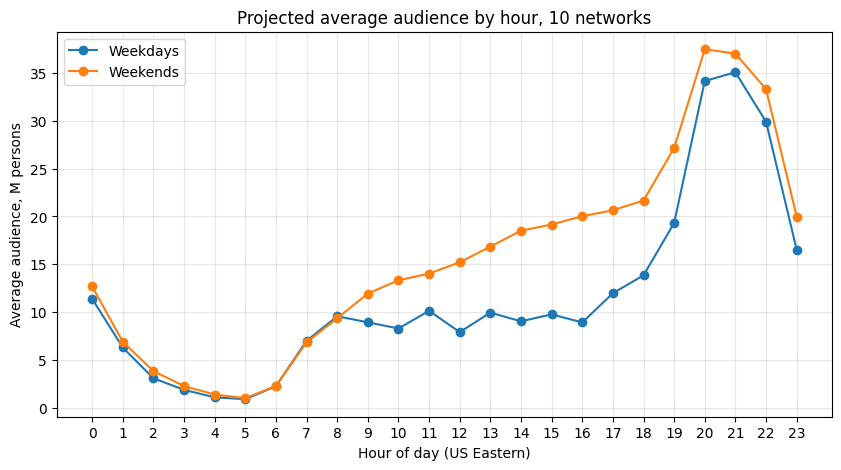

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [17]:
# plot: projected average audience (M) by clock hour, weekday vs weekend
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(weekday_aud.index, weekday_aud, marker="o", label="Weekdays")
ax.plot(weekend_aud.index, weekend_aud, marker="o", label="Weekends")
ax.set_xticks(range(24))
ax.set_xlabel("Hour of day (US Eastern)")
ax.set_ylabel("Average audience, M persons")
ax.set_title("Projected average audience by hour, 10 networks")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("Peak hour, weekdays:", weekday_aud.idxmax())
print("Peak hour, weekends:", weekend_aud.idxmax())

**Answer:** The peak is in prime time on both: at 21:00 on weekdays and at 20:00 on weekends. Weekdays and weekends have a lot in common but also differ. The main difference I see is the 9-18 segment, when most people work: on weekdays the average audience stays on a plateau there, whereas on weekends it keeps growing through the day. Also, weekends have the same or a bigger audience than weekdays at every hour except 7-8 in the morning, when people watch morning news before work.

## Task 1.3 — Session length

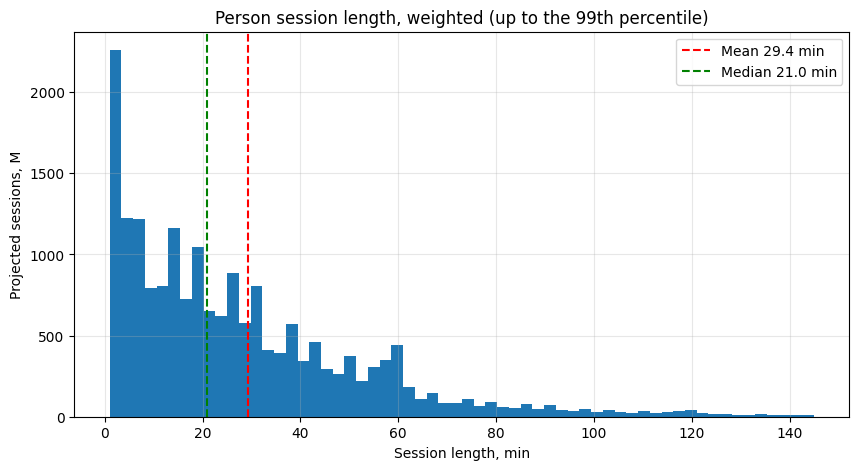

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [18]:
length = (person_viewings["end_ts"] - person_viewings["start_ts"]) / ONE_MINUTE
weight = person_viewings["weight"]

w_mean = (length * weight).sum() / weight.sum()
w_median = weighted_quantile(length, weight, 0.5)

# plot: weighted distribution of person session length (long tail cut at the 99th percentile for readability)
cutoff = weighted_quantile(length, weight, 0.99)
shown = length <= cutoff
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(length[shown], bins=60, weights=weight[shown] / 1e6)
ax.axvline(w_mean, color="red", linestyle="--", label=f"Mean {w_mean:.1f} min")
ax.axvline(w_median, color="green", linestyle="--", label=f"Median {w_median:.1f} min")
ax.set_xlabel("Session length, min")
ax.set_ylabel("Projected sessions, M")
ax.set_title("Person session length, weighted (up to the 99th percentile)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("Session length, weighted mean (min):", f"{w_mean:.1f}")
print("Session length, weighted median (min):", f"{w_median:.1f}")

**Answer:** The mean (29.4 min) is much greater than the median (21 min) because the distribution has a long tail: most sessions are short, but some people have very long sessions that pull the average up. The median is a more reasonable "typical" value in this situation, so I would show the median to a client.

## Task 2 — Program reach curve

In [19]:
def target_ids(min_age=2, max_age=np.inf, sex=None):
    """Ids of persons with age in [min_age, max_age] and sex "Male" / "Female" / None (both)."""
    t = persons[persons["age"].between(min_age, max_age)]
    if sex is not None:
        t = t[t["sex"] == sex]
    return set(t.index)


HH = set(daily_weights.loc[daily_weights["resp_type"] == "H", "respondent_id"])
P2 = target_ids(2)
A18_34 = target_ids(18, 34)
A18_49 = target_ids(18, 49)


def telecast_viewers(tc, target):
    """Ids from the target who watched at least 1 minute of the telecast."""
    v = viewings[(viewings["network_code"] == tc.network_code)
                 & (viewings["start_ts"] < tc.end_ts)
                 & (viewings["end_ts"] > tc.start_ts)
                 & viewings["respondent_id"].isin(target)]
    # minutes of each session inside the telecast
    overlap = (v["end_ts"].clip(upper=tc.end_ts) - v["start_ts"].clip(lower=tc.start_ts)) / ONE_MINUTE
    minutes_per_viewer = overlap.groupby(v["respondent_id"]).sum()
    return set(minutes_per_viewer[minutes_per_viewer >= 1].index)


def telecast_rating(tc, target):
    """Rating (%) and projected audience of the telecast for the target."""
    in_tab = daily_weights[(daily_weights["broadcast_date"] == tc.broadcast_date)
                           & daily_weights["respondent_id"].isin(target)]
    viewers = telecast_viewers(tc, target)
    audience = in_tab.loc[in_tab["respondent_id"].isin(viewers), "weight"].sum()
    return 100 * audience / in_tab["weight"].sum(), audience


cbs_evening_news = (programs[(programs["network_code"] == "CBS") & (programs["program_name"] == "CBS Evening News")]
                    .sort_values("start_ts"))

# table: household rating, P2+ rating, projected audience (M) per telecast
rows = []
for tc in cbs_evening_news.itertuples():
    hh_rating, _ = telecast_rating(tc, HH)
    p2_rating, p2_audience = telecast_rating(tc, P2)
    rows.append({"broadcast_date": tc.broadcast_date,
                 "hh_rating": hh_rating,
                 "p2_rating": p2_rating,
                 "audience_M": p2_audience / 1e6})
ratings = pd.DataFrame(rows)
ratings.round(2)

,broadcast_date,hh_rating,p2_rating,audience_M
0,2024-10-01,3.47,1.67,5.28
1,2024-10-02,3.07,1.48,4.68
2,2024-10-03,2.99,1.47,4.68
3,2024-10-04,3.00,1.51,4.81
4,2024-10-07,3.06,1.52,4.83
5,2024-10-08,3.17,1.57,4.97
6,2024-10-09,2.98,1.48,4.70
7,2024-10-10,3.38,1.62,5.13
8,2024-10-11,3.09,1.48,4.69
9,2024-10-14,2.93,1.45,4.59


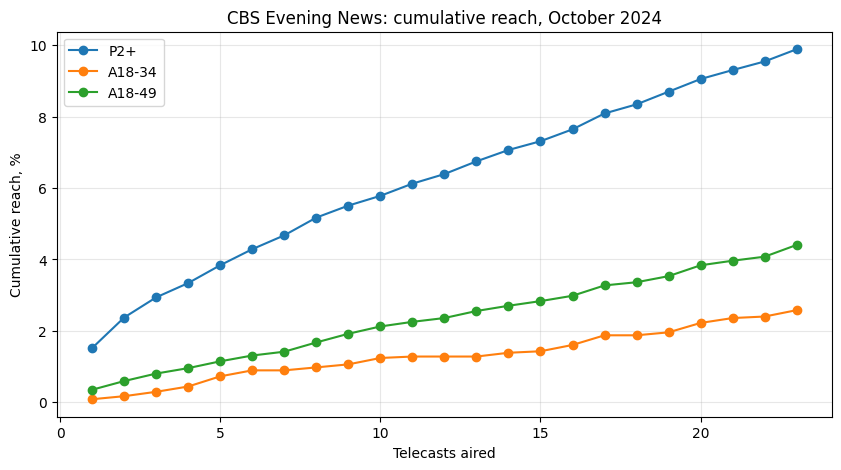

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [20]:
# one weight per person for the month: average over in-tab days
monthly_weight = daily_weights.groupby("respondent_id")["weight"].mean()


def cumulative_reach(telecasts, target):
    """Cumulative reach (%) of the target after each telecast, in air order."""
    target_weight = monthly_weight[monthly_weight.index.isin(target)]
    reached = set()
    reach = []
    for tc in telecasts.sort_values("start_ts").itertuples():
        reached |= telecast_viewers(tc, target)
        reach.append(100 * target_weight[target_weight.index.isin(reached)].sum() / target_weight.sum())
    return reach


reach = pd.DataFrame({
    "P2+": cumulative_reach(cbs_evening_news, P2),
    "A18-34": cumulative_reach(cbs_evening_news, A18_34),
    "A18-49": cumulative_reach(cbs_evening_news, A18_49),
}, index=range(1, len(cbs_evening_news) + 1))

# plot: cumulative reach P2+, A18-34, A18-49
fig, ax = plt.subplots(figsize=(10, 5))
for col in reach.columns:
    ax.plot(reach.index, reach[col], marker="o", label=col)
ax.set_xlabel("Telecasts aired")
ax.set_ylabel("Cumulative reach, %")
ax.set_title("CBS Evening News: cumulative reach, October 2024")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("Telecasts of the program:", len(ratings))
print("Average household rating (%):", f"{ratings['hh_rating'].mean():.1f}")
print("Average P2+ rating (%):", f"{ratings['p2_rating'].mean():.1f}")
print("Average projected audience (M):", f"{ratings['audience_M'].mean():.2f}")
print("Final reach P2+ (%):", f"{reach['P2+'].iloc[-1]:.1f}")
print("Final reach A18-34 (%):", f"{reach['A18-34'].iloc[-1]:.1f}")
print("Final reach A18-49 (%):", f"{reach['A18-49'].iloc[-1]:.1f}")

In [21]:
# extra audiences for the answer
print("Final reach A50+ (%):", f"{cumulative_reach(cbs_evening_news, target_ids(50))[-1]:.1f}")
print("Final reach P2-17 (%):", f"{cumulative_reach(cbs_evening_news, target_ids(2, 17))[-1]:.1f}")

Final reach A50+ (%): 19.1
Final reach P2-17 (%): 4.3


**Answer:** Cumulative reach keeps growing because each telecast is watched by a slightly different set of people. There is a small loyal core who watch almost every day, but most viewers watch only from time to time, so every new telecast brings some new people while the rating stays about the same. Reach grows almost linearly because there are many such occasional viewers and one month is not enough to reach them all. The program reaches older people best: final reach is 19.1% for A50+ against only 4.4% for A18-49 and 2.6% for A18-34, and P2+ (9.9%) is high mostly because of the 50+ viewers. This matches what we know about evening news: it is watched mostly by older people, while young people get their news online.

## Task 3 — Program frequency

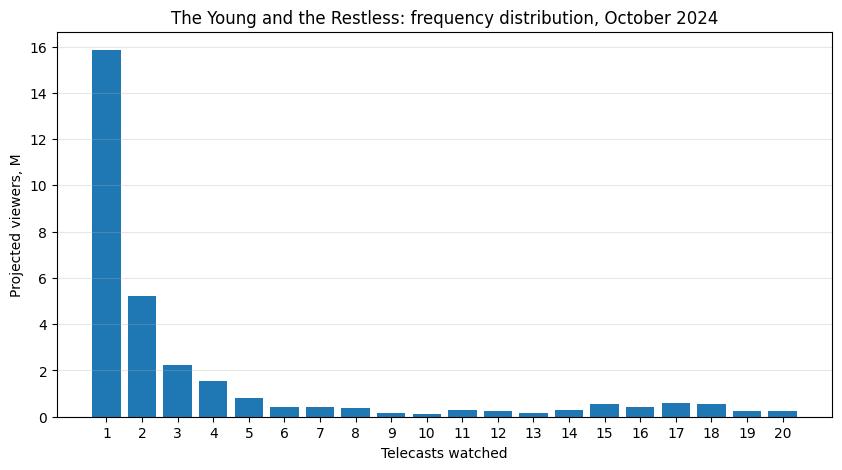

Projected viewers (M): 30.80
Average frequency (weighted): 3.63
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704


In [22]:
yr_telecasts = programs[(programs["network_code"] == "CBS")
                        & (programs["program_name"] == "The Young and the Restless")]

# frequency: how many telecasts each person watched
watched = [pid for tc in yr_telecasts.itertuples() for pid in telecast_viewers(tc, P2)]
viewers = pd.Series(watched).value_counts().rename("frequency").to_frame()
viewers["weight"] = monthly_weight.reindex(viewers.index)

# projected viewers by frequency level
dist = viewers.groupby("frequency")["weight"].sum()
total = dist.sum()

w_mean = (viewers["frequency"] * viewers["weight"]).sum() / total
w_median = weighted_quantile(viewers["frequency"], viewers["weight"], 0.5)
p80 = weighted_quantile(viewers["frequency"], viewers["weight"], 0.8)

# views = frequency x weight; the most loyal are at or above the 80th percentile
views = dist.index * dist
loyal_share = views[views.index >= p80].sum() / views.sum()

# plot: projected viewers (M) by number of telecasts watched
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(dist.index, dist / 1e6)
ax.set_xticks(dist.index)
ax.set_xlabel("Telecasts watched")
ax.set_ylabel("Projected viewers, M")
ax.set_title("The Young and the Restless: frequency distribution, October 2024")
ax.grid(alpha=0.3, axis="y")
plt.show()

print("Projected viewers (M):", f"{total / 1e6:.2f}")
print("Average frequency (weighted):", f"{w_mean:.2f}")
print("Median frequency (weighted):", w_median)
print("Share of views from the most loyal viewers:", f"{loyal_share:.3f}")

In [23]:
# extra numbers for the answer
print("Telecasts of the program:", len(yr_telecasts))
print("80th percentile of frequency:", p80)
print("Share of viewers who are the most loyal:", f"{dist[dist.index >= p80].sum() / total:.3f}")
print("Share of viewers who watched once:", f"{dist[1] / total:.3f}")

Telecasts of the program: 23
80th percentile of frequency: 4
Share of viewers who are the most loyal: 0.243
Share of viewers who watched once: 0.515


**Answer:** The average frequency is not a fair summary because the distribution is very skewed. The median is 1: 51.5% of the viewers watched the show only once in October. The average is 3.6 only because of the loyal viewers: those who watched 4+ telecasts are about 24% of the viewers, but they generate 70.4% of all views. So "an average viewer watched 3.6 episodes" describes almost nobody: the audience is a mix of a small group of fans and a big group of people who watched once or twice.

## Task 4 — Networks by age and gender

In [24]:
# person sessions with age and sex; each session weighted by the person's weight for that broadcast day
sessions = person_viewings.join(persons, on="respondent_id")
sessions["minutes"] = (sessions["end_ts"] - sessions["start_ts"]) / ONE_MINUTE
sessions["proj_minutes"] = sessions["minutes"] * sessions["weight"]

audiences = {
    "M18-34": (18, 34, "Male"),
    "W18-34": (18, 34, "Female"),
    "M35-54": (35, 54, "Male"),
    "W35-54": (35, 54, "Female"),
    "M55+": (55, np.inf, "Male"),
    "W55+": (55, np.inf, "Female"),
}

# six top-5 tables (projected minutes): M18-34, W18-34, M35-54, W35-54, M55+, W55+
for name, (min_age, max_age, sex) in audiences.items():
    in_audience = sessions["age"].between(min_age, max_age) & (sessions["sex"] == sex)
    top5 = sessions[in_audience].groupby("network_code")["proj_minutes"].sum().nlargest(5) / 1e6
    display(top5.round(2).rename(f"{name}: projected minutes (M)").to_frame())

,M18-34: projected minutes (M)
network_code,
FOX,4386.65
NBC,3910.39
CBS,3044.35
ABC,3010.78
FX,1473.96


,W18-34: projected minutes (M)
network_code,
FOX,4574.44
NBC,4527.59
ABC,3504.86
CBS,2811.22
FX,1383.47


,M35-54: projected minutes (M)
network_code,
FOX,12804.67
NBC,10986.68
ABC,9037.00
CBS,8134.07
FX,2370.80


,W35-54: projected minutes (M)
network_code,
NBC,11639.10
FOX,11161.39
ABC,9438.56
CBS,8162.80
HGTV,3051.81


,M55+: projected minutes (M)
network_code,
CBS,38274.03
NBC,34267.41
FOX,30878.51
ABC,30793.34
FNC,27903.71


,W55+: projected minutes (M)
network_code,
CBS,47120.32
NBC,41391.87
ABC,38840.01
FOX,36914.72
FNC,31450.73


In [25]:
# table: 18-34 share of minutes per network, weighted and raw
is_18_34 = sessions["age"].between(18, 34)
by_network = sessions.groupby("network_code")
young_by_network = sessions[is_18_34].groupby("network_code")
share_18_34 = pd.DataFrame({
    "weighted": young_by_network["proj_minutes"].sum() / by_network["proj_minutes"].sum(),
    "raw": young_by_network["minutes"].sum() / by_network["minutes"].sum(),
}).sort_values("weighted", ascending=False)
share_18_34["difference"] = share_18_34["weighted"] - share_18_34["raw"]
display(share_18_34.round(3))

print("Youngest network:", share_18_34["weighted"].idxmax())
print("Oldest network:", share_18_34["weighted"].idxmin())

,weighted,raw,difference
network_code,,,
FX,0.266,0.232,0.034
BRAVO,0.148,0.127,0.021
FOX,0.082,0.075,0.007
FOOD,0.078,0.071,0.007
NBC,0.073,0.068,0.005
ABC,0.064,0.060,0.004
HGTV,0.058,0.052,0.006
CBS,0.051,0.050,0.002
HIST,0.048,0.044,0.004


Youngest network: FX
Oldest network: FNC


In [26]:
# age structure of the panel vs the US population it stands for (person-days)
age_group = pd.cut(person_weights["respondent_id"].map(persons["age"]),
                   bins=[0, 17, 34, 54, np.inf], labels=["2-17", "18-34", "35-54", "55+"])
composition = pd.DataFrame({
    "panel": person_weights.groupby(age_group, observed=True).size() / len(person_weights),
    "weighted (US)": person_weights.groupby(age_group, observed=True)["weight"].sum() / person_weights["weight"].sum(),
})
composition.round(3)

,panel,weighted (US)
respondent_id,,
2-17,0.216,0.204
18-34,0.197,0.229
35-54,0.333,0.254
55+,0.254,0.313


**Answer:** The youngest network is FX (26.6% of its minutes come from 18-34) and the oldest is FNC (only 1.8%). Without weights the 18-34 share is lower on every network, and the biggest difference is on FX, the network with the youngest audience. It happens because young adults are under-represented in our panel: 18-34 are 19.7% of panel members but 22.9% of the US population, so each young panelist gets a bigger weight. People aged 35-54 are over-represented (33.3% in the panel against 25.4% in the US). If we reported raw panel numbers to a client, we would underestimate young (and also 55+) audiences and overestimate 35-54, so networks with young audiences like FX and Bravo would look smaller and older than they really are.

**Bonus answer:** I would not sell FNC as the main channel for young adults, because only 1.8% of its minutes come from 18-34. Instead, I would pitch it as an add-on to a campaign on younger networks like FX or FOX: the few young people who watch Fox News are engaged news viewers, especially before the election, they may not be reached by the rest of the plan, and since nobody buys FNC for young adults, these impressions should be cheap.